In [214]:
import pandas as pd
import numpy as np

# Plotting
import matplotlib.pyplot as plt

# Data, Processing, & Validation
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Machine Learning Models
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.svm import SVR
from sklearn.neural_network import MLPRegressor
from sklearn.neighbors import KNeighborsRegressor

# Statistics
from scipy import stats

# Question 4: Normal Residuals

In [215]:
fh = 'mcs_ds_edited_iter_shuffled.csv'

df = pd.read_csv(fh)

df.sample(n = 3)

,anchor_ratio,trans_range,node_density,iterations,ale,sd_ale
12,18,23,100,24,1.054097,0.312640
100,22,18,100,48,1.188537,0.353485
47,30,20,100,100,0.798877,0.208753


In [216]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 107 entries, 0 to 106
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   anchor_ratio  107 non-null    int64  
 1   trans_range   107 non-null    int64  
 2   node_density  107 non-null    int64  
 3   iterations    107 non-null    int64  
 4   ale           107 non-null    float64
 5   sd_ale        107 non-null    float64
dtypes: float64(2), int64(4)
memory usage: 5.1 KB


In [217]:
X = df.loc[:, ['anchor_ratio', 'trans_range', 'node_density', 'iterations']].values
y = df.loc[:, 'ale'].values

scaler1  = StandardScaler()
X_scaled = scaler1.fit_transform(X)

### [Linear Regression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html#sklearn.linear_model.LinearRegression)

In [218]:
lin_reg = LinearRegression()

lin_reg.fit(X_scaled, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [219]:
r = y - lin_reg.predict(X_scaled)

In [220]:
norm_res = stats.normaltest(r)

print(f"p-value: {norm_res.pvalue:0.4f}\nSignificant: {norm_res.pvalue < 0.01}")

p-value: 0.0000
Significant: True


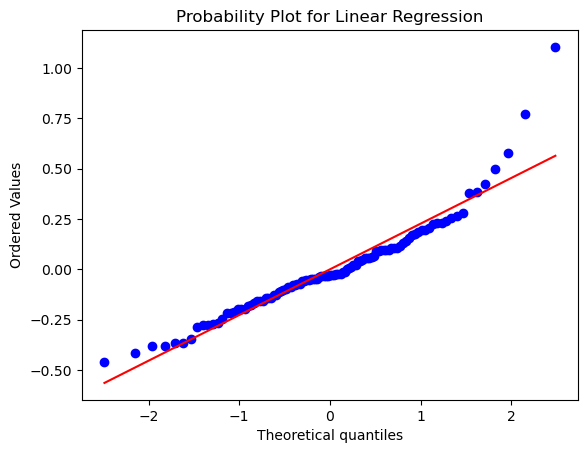

In [221]:
stats.probplot(r, plot=plt)
plt.title("Probability Plot for Linear Regression")
plt.show()

### [Ridge](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html)

In [222]:
ridge = Ridge(alpha=.5)

ridge.fit(X_scaled, y)

,"alpha alpha: {float, ndarray of shape (n_targets,)}, default=1.0Constant that multiplies the L2 term, controlling regularizationstrength. `alpha` must be a non-negative float i.e. in `[0, inf)`.When `alpha = 0`, the objective is equivalent to ordinary leastsquares, solved by the :class:`LinearRegression` object. For numericalreasons, using `alpha = 0` with the `Ridge` object is not advised.Instead, you should use the :class:`LinearRegression` object.If an array is passed, penalties are assumed to be specific to thetargets. Hence they must correspond in number.",0.5
,"fit_intercept fit_intercept: bool, default=TrueWhether to fit the intercept for this model. If setto false, no intercept will be used in calculations(i.e. ``X`` and ``y`` are expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"max_iter max_iter: int, default=NoneMaximum number of iterations for conjugate gradient solver.For 'sparse_cg' and 'lsqr' solvers, the default value is determinedby scipy.sparse.linalg. For 'sag' solver, the default value is 1000.For 'lbfgs' solver, the default value is 15000.",None
,"tol tol: float, default=1e-4The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for each solver:- 'svd': `tol` has no impact.- 'cholesky': `tol` has no impact.- 'sparse_cg': norm of residuals smaller than `tol`.- 'lsqr': `tol` is set as atol and btol of scipy.sparse.linalg.lsqr, which control the norm of the residual vector in terms of the norms of matrix and coefficients.- 'sag' and 'saga': relative change of coef smaller than `tol`.- 'lbfgs': maximum of the absolute (projected) gradient=max|residuals| smaller than `tol`... versionchanged:: 1.2 Default value changed from 1e-3 to 1e-4 for consistency with other linear models.",0.0001
,"solver solver: {'auto', 'svd', 'cholesky', 'lsqr', 'sparse_cg', 'sag', 'saga', 'lbfgs'}, default='auto'Solver to use in the computational routines:- 'auto' chooses the solver automatically based on the type of data.- 'svd' uses a Singular Value Decomposition of X to compute the Ridge coefficients. It is the most stable solver, in particular more stable for singular matrices than 'cholesky' at the cost of being slower.- 'cholesky' uses the standard :func:`scipy.linalg.solve` function to obtain a closed-form solution.- 'sparse_cg' uses the conjugate gradient solver as found in :func:`scipy.sparse.linalg.cg`. As an iterative algorithm, this solver is more appropriate than 'cholesky' for large-scale data (possibility to set `tol` and `max_iter`).- 'lsqr' uses the dedicated regularized least-squares routine :func:`scipy.sparse.linalg.lsqr`. It is the fastest and uses an iterative procedure.- 'sag' uses a Stochastic Average Gradient descent, and 'saga' uses its improved, unbiased version named SAGA. Both methods also use an iterative procedure, and are often faster than other solvers when both n_samples and n_features are large. Note that 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`.- 'lbfgs' uses L-BFGS-B algorithm implemented in :func:`scipy.optimize.minimize`. It can be used only when `positive` is True.All solvers except 'svd' support both dense and sparse data. However, only'lsqr', 'sag', 'sparse_cg', and 'lbfgs' support sparse input when`fit_intercept` is True... versionadded:: 0.17 Stochastic Average Gradient descent solver... versionadded:: 0.19 SAGA solver.",'auto'
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive.Only 'lbfgs' solver is supported in this case.",False
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag' or 'saga' to shuffle the data.See :term:`Glossary ` for details... versionadded:: 0.17 `random_state` to support Stochastic Average Gradient.",None


In [223]:
r = y - ridge.predict(X_scaled)

In [224]:
norm_res = stats.normaltest(r)

print(f"p-value: {norm_res.pvalue:0.4f}\nSignificant: {norm_res.pvalue < 0.01}")

p-value: 0.0000
Significant: True


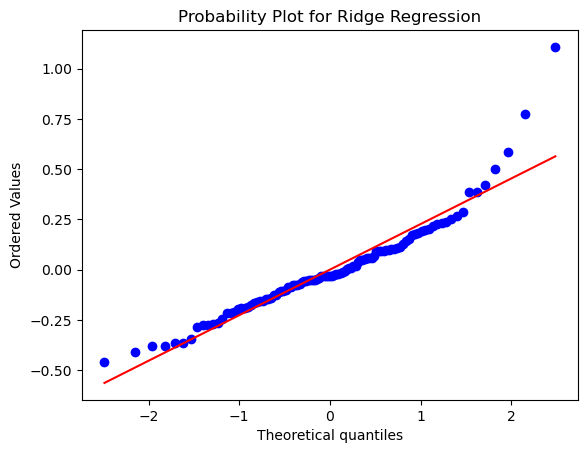

In [225]:
stats.probplot(r, plot=plt)
plt.title("Probability Plot for Ridge Regression")
plt.show()

### [Support Vector Regression](https://scikit-learn.org/stable/modules/generated/sklearn.svm.SVR.html#sklearn.svm.SVR)

In [226]:
svr = SVR()

svr.fit(X_scaled, y)

,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm.If none is given, 'rbf' will be used. If a callable is given it isused to precompute the kernel matrix.For an intuitive visualization of different kernel typessee :ref:`sphx_glr_auto_examples_svm_plot_svm_regression.py`",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive.The penalty is a squared l2. For an intuitive visualization of theeffects of scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-SVR model. It specifies the epsilon-tubewithin which no penalty is associated in the training loss functionwith points predicted within a distance epsilon from the actualvalue. Must be non-negative.",0.1
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False
,"max_iter max_iter: int, default=-1Hard limit on iterations within solver, or -1 for no limit.",-1


In [227]:
r = y - svr.predict(X_scaled)

In [228]:
norm_res = stats.normaltest(r)

print(f"p-value: {norm_res.pvalue:0.4f}\nSignificant: {norm_res.pvalue < 0.01}")

p-value: 0.0000
Significant: True


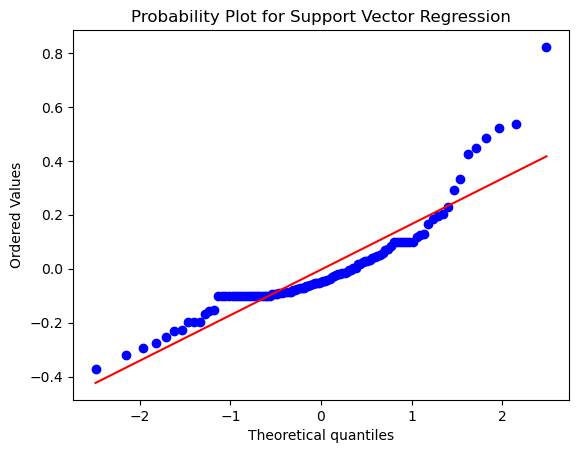

In [229]:
stats.probplot(r, plot=plt)
plt.title("Probability Plot for Support Vector Regression")
plt.show()

### [K-Nearest Neighbors Regression](https://scikit-learn.org/stable/modules/generated/sklearn.neighbors.KNeighborsRegressor.html#sklearn.neighbors.KNeighborsRegressor)

In [230]:
knn_reg = KNeighborsRegressor()

knn_reg.fit(X_scaled, y)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Uniform weights are used by default.See the following example for a demonstration of the impact ofdifferent weighting schemes on predictions::ref:`sphx_glr_auto_examples_neighbors_plot_regression.py`.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this isequivalent to using manhattan_distance (l1), and euclidean_distance(l2) for p = 2. For arbitrary p, minkowski_distance (l_p) is used.",2
,"metric metric: str, DistanceMetric object or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.If metric is a DistanceMetric object, it will be passed directly tothe underlying computation routines.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details.Doesn't affect :meth:`fit` method.",None


In [231]:
r = y - knn_reg.predict(X_scaled)

In [232]:
norm_res = stats.normaltest(r)

print(f"p-value: {norm_res.pvalue:0.4f}\nSignificant: {norm_res.pvalue < 0.01}")

p-value: 0.0000
Significant: True


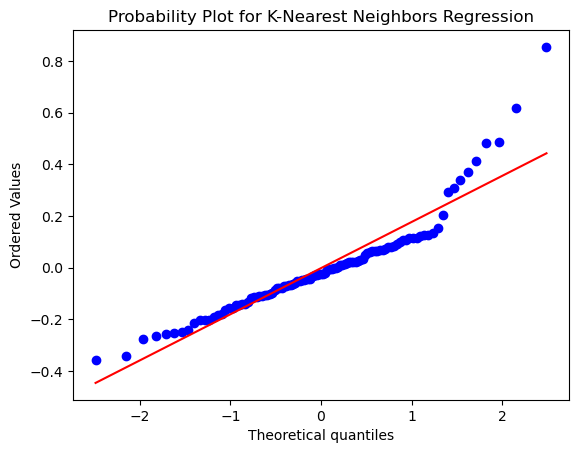

In [233]:
stats.probplot(r, plot=plt)
plt.title("Probability Plot for K-Nearest Neighbors Regression")
plt.show()

### [Multi-layer Perceptron Regression](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPRegressor.html#sklearn.neural_network.MLPRegressor)

In [234]:
mlp_reg = MLPRegressor(max_iter=2000, random_state=42)

mlp_reg.fit(X_scaled, y)

,"loss loss: {'squared_error', 'poisson'}, default='squared_error'The loss function to use when training the weights. Note that the""squared error"" and ""poisson"" losses actually implement""half squares error"" and ""half poisson deviance"" to simplify thecomputation of the gradient. Furthermore, the ""poisson"" loss internally usesa log-link (exponential as the output activation function) and requires``y >= 0``... versionchanged:: 1.7 Added parameter `loss` and option 'poisson'.",'squared_error'
,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(100,)"
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.",0.0001
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the regressor will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate ``learning_rate_`` at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when solver='sgd'.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",2000
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


In [235]:
r = y - mlp_reg.predict(X_scaled)

In [236]:
norm_res = stats.normaltest(r)

print(f"p-value: {norm_res.pvalue:0.4f}\nSignificant: {norm_res.pvalue < 0.01}")

p-value: 0.0010
Significant: True


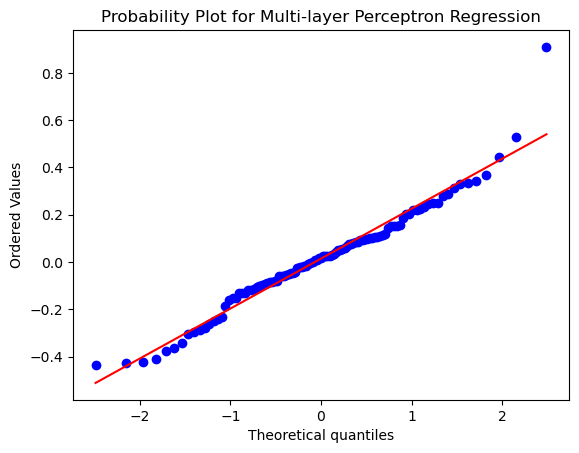

In [237]:
stats.probplot(r, plot=plt)
plt.title("Probability Plot for Multi-layer Perceptron Regression")
plt.show()

# Question 5: 

In [238]:
import torch

In [239]:
data = load_breast_cancer()

data.keys()

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])

In [240]:
feature_names = data['feature_names']
target_names  = data['target_names']

X = data['data']
y = data['target']

In [241]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

## Classification

In [242]:
log_reg_model = LogisticRegression()

In [243]:
log_reg_model.fit(X_train_s, y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [244]:
predictions = log_reg_model.predict(X_test_s)

sklearn_accuracy = np.mean(predictions == y_test)

f"Accuracy: {sklearn_accuracy*100:.4}%"

'Accuracy: 97.37%'

In [245]:
"""Accuracy: 97.37%"""

'Accuracy: 97.37%'

### Classification (a)

In [246]:
X_train_s_tensor = torch.tensor(X_train_s, dtype=torch.float32)
X_test_s_tensor  = torch.tensor(X_test_s, dtype=torch.float32)
y_train_tensor   = torch.tensor(y_train, dtype=torch.float32)
y_test_tensor    = torch.tensor(y_test, dtype=torch.float32)

In [247]:
class LogReg(torch.nn.Module):
    def __init__(self, d):
        super().__init__()

        self.w = torch.nn.Parameter(torch.zeros(d))
        self.b = torch.nn.Parameter(torch.zeros(1))

    def sigmoid(self, y):
        return 1 / (1 + torch.e**(-y))

    def forward(self, x):
        """Logistic Regression"""
        return self.sigmoid(x @ self.w + self.b)

In [248]:
def bce_loss(y, p, epsilon: float = 1e-7):
    "Binary Cross Entropy Loss"
    p = torch.clamp(p, epsilon, 1 - epsilon)
    return -(y * torch.log(p) + (1 - y) * torch.log(1 - p))

In [249]:
n_steps: int = 2_000
lr: float = 0.001

np.random.seed(42)

In [250]:
n, m = X_train_s_tensor.shape

In [251]:
model = LogReg(d = m)
optimizer = torch.optim.SGD(model.parameters(), lr = lr, maximize=False)

In [252]:
for _ in range(n_steps):
    rand_idx = np.random.randint(low=0, high=n)     # Choose a single random sample (index) from the training data

    optimizer.zero_grad()
    loss = bce_loss(y = y_train_tensor[rand_idx], p = model(X_train_s_tensor[rand_idx, :]))
    loss.backward()
    optimizer.step()

In [253]:
with torch.no_grad():
    predictions = model(X_test_s_tensor)
    torch_accuracy  = ((predictions >= 0.5).float() == y_test_tensor).float().mean().item()

print(f"pytorch accuracy: {torch_accuracy*100:0.2f}%")
print(f"sklearn accuracy: {sklearn_accuracy*100:0.2f}%")

pytorch accuracy: 98.25%
sklearn accuracy: 97.37%


In [254]:
"""
pytorch accuracy: 98.25%
sklearn accuracy: 97.37%

The PyTorch implementation performs marginally better than the scikit-learn (baseline) implementation.
"""

'\npytorch accuracy: 98.25%\nsklearn accuracy: 97.37%\n\nThe PyTorch implementation performs marginally better than the scikit-learn (baseline) implementation.\n'

### Classification (b)

In [255]:
class ProbitReg(torch.nn.Module):
    def __init__(self, d, loc: float = 0, scale: float = 1):
        super().__init__()

        assert scale >= 0

        self.w = torch.nn.Parameter(torch.zeros(d))
        self.b = torch.nn.Parameter(torch.zeros(1))

        self.normal = torch.distributions.Normal(loc, scale)

    def forward(self, x):
        return self.normal.cdf(x @ self.w + self.b)

In [256]:
model = ProbitReg(d = m)
optimizer = torch.optim.SGD(model.parameters(), lr = lr, maximize = False)

In [257]:
for _ in range(n_steps):
    rand_idx = np.random.randint(low = 0, high = n)     

    optimizer.zero_grad()
    loss = bce_loss(y = y_train_tensor[rand_idx], p = model(X_train_s_tensor[rand_idx, :]))
    loss.backward()
    optimizer.step()

In [258]:
with torch.no_grad():
    predictions = model(X_test_s_tensor)
    torch_probit_accuracy = ((predictions >= 0.5).float() == y_test_tensor).float().mean().item()

print(f"pytorch probit accuracy: {torch_probit_accuracy*100:0.2f}%")
print(f"sklearn accuracy: {sklearn_accuracy*100:0.2f}%")

pytorch probit accuracy: 98.25%
sklearn accuracy: 97.37%


In [259]:
"""
pytorch probit accuracy: 98.25%
sklearn accuracy: 97.37%

Similar to before, the PyTorch implementation (this time using probit) 
performs marginally better than the scikit-learn (baseline) implementation.
"""

'\npytorch probit accuracy: 98.25%\nsklearn accuracy: 97.37%\n\nSimilar to before, the PyTorch implementation (this time using probit) \nperforms marginally better than the scikit-learn (baseline) implementation.\n'

## Regression

In [260]:
df.sample(n = 3)

,anchor_ratio,trans_range,node_density,iterations,ale,sd_ale
68,15,15,300,60,0.644283,0.079024
76,15,15,100,90,1.204298,0.349469
57,18,23,100,22,0.982107,0.183158


In [261]:
X = df.loc[:, ['anchor_ratio', 'trans_range', 'node_density', 'iterations']].values
y = df.loc[:, 'ale'].values

In [262]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size = 0.20, random_state=42)

In [263]:
scaler = StandardScaler()

X_tr_s = scaler.fit_transform(X_tr)
X_te_s = scaler.transform(X_te)

In [264]:
model = LinearRegression()

In [265]:
model.fit(X = X_tr_s, y = y_tr)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies a different convergence criterion for the `lsqr` solver.`tol` is set as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. This parameter has no effect when fittingon dense data... versionadded:: 1.7",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary ` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False


In [266]:
predictions = model.predict(X_te_s)

In [267]:
def mae(y, pred):
    return sum(abs(y - pred)) / len(y)

In [268]:
sklearn_mae = mae(y_te, predictions)

f"sklearn accuracy (mae) {sklearn_mae:.4f}"

'sklearn accuracy (mae) 0.1954'

In [269]:
"""sklearn accuracy (mae) 0.1954"""

'sklearn accuracy (mae) 0.1954'

### Regression (a)

In [270]:
X_tr_s_tensor = torch.tensor(X_tr_s, dtype=torch.float32)
X_te_s_tensor = torch.tensor(X_te_s, dtype=torch.float32)
y_tr_tensor   = torch.tensor(y_tr, dtype=torch.float32)
y_te_tensor   = torch.tensor(y_te, dtype=torch.float32)

In [271]:
class LinReg(torch.nn.Module):
    def __init__(self, d):
        super().__init__()

        self.w = torch.nn.Parameter(torch.zeros(d, dtype=torch.float32))
        self.b = torch.nn.Parameter(torch.zeros(1, dtype=torch.float32))

    def forward(self, x):
        return x @ self.w + self.b

In [272]:
def mse_loss(y, pred):
    v = y - pred
    return (v ** 2).mean()

In [273]:
n, m = X_tr_s_tensor.shape

In [274]:
model = LinReg(d = m)
optimizer = torch.optim.SGD(params = model.parameters(), lr = lr, maximize = False)

In [275]:
for _ in range(n_steps):
    rand_idx = np.random.randint(low=0, high=n)

    optimizer.zero_grad()
    loss = mse_loss(y_tr_tensor[rand_idx], model(X_tr_s_tensor[rand_idx, :]))
    loss.backward()
    optimizer.step()

In [276]:
with torch.no_grad():
    predictions = model(X_te_s_tensor)
    torch_lin_reg_mae = mae(y_te_tensor, predictions)

print(f"pytorch linear regression performance (mae): {torch_lin_reg_mae:0.4f}")
print(f"sklearn linear regression performance (mae): {sklearn_mae:0.4f}")

pytorch linear regression performance (mae): 0.2020
sklearn linear regression performance (mae): 0.1954


In [277]:
"""
pytorch linear regression performance (mae): 0.2020
sklearn linear regression performance (mae): 0.1954

The Mean Absolute Error of the PyTorch implementation slightly exceeds that of the scikit-learn (baseline) implementation, 
signalling that the baseline is a marginally better model.
"""

'\npytorch linear regression performance (mae): 0.2020\nsklearn linear regression performance (mae): 0.1954\n\nThe Mean Absolute Error of the PyTorch implementation slightly exceeds that of the scikit-learn (baseline) implementation, \nsignalling that the baseline is a marginally better model.\n'

### Regression (b)

In [278]:
nu = 5

In [279]:
def nll(y, pred):
    q = y - pred
    t_dist = torch.distributions.StudentT(df = nu)
    return -t_dist.log_prob(q)

In [280]:
n, m = X_tr_s_tensor.shape

In [281]:
model = LinReg(d = m)
optimizer = torch.optim.SGD(params = model.parameters(), lr = lr, maximize = False)

In [282]:
for _ in range(n_steps):
    rand_idx = np.random.randint(low = 0, high = n)

    optimizer.zero_grad()
    loss = nll(y_tr_tensor[rand_idx], model(X_tr_s_tensor[rand_idx, :]))
    loss.backward()
    optimizer.step()

In [283]:
with torch.no_grad():
    predictions = model(X_te_s_tensor)
    torch_lin_reg_mae = mae(y_te_tensor, predictions)

print(f"pytorch linear regression performance (mae): {torch_lin_reg_mae:0.2f}")
print(f"sklearn linear regression performance (mae): {sklearn_mae:0.2f}")

pytorch linear regression performance (mae): 0.24
sklearn linear regression performance (mae): 0.20


In [284]:
"""
pytorch linear regression performance (mae): 0.24
sklearn linear regression performance (mae): 0.20

The Mean Absolute Error of the PyTorch implementation slightly exceeds that of the scikit-learn (baseline) 
implementation, signalling that the baseline is a marginally better model. This is expected, as PyTorch uses SGD, 
which is an approximation of the optimum, whereas scikit-learn solves the least squares problem in closed form, 
which guarantees the optimum.
"""

'\npytorch linear regression performance (mae): 0.24\nsklearn linear regression performance (mae): 0.20\n\nThe Mean Absolute Error of the PyTorch implementation slightly exceeds that of the scikit-learn (baseline) \nimplementation, signalling that the baseline is a marginally better model. This is expected, as PyTorch uses SGD, \nwhich is an approximation of the optimum, whereas scikit-learn solves the least squares problem in closed form, \nwhich guarantees the optimum.\n'